# DAS7002 Big Data Technologies — PRAC 1

## Task 3: Unsupervised Learning — Spatial and Temporal Crime Clustering

This task applies distributed unsupervised machine learning to identify patterns of crime activity that emerge independently of Chicago's official administrative boundaries.

K-Means clustering is applied using geographic and temporal characteristics of reported crime, including latitude, longitude, and time of day.

The analysis will:

- prepare valid spatial and temporal features for clustering,
- standardise features to prevent differences in measurement scale from dominating the model,
- evaluate alternative values of K using clustering-quality metrics,
- train a final distributed K-Means model using Spark ML,
- analyse the resulting cluster centres and crime volumes,
- compare data-driven crime clusters with official police-district boundaries,
- and discuss the trade-off between statistical cluster quality and operational interpretability.

The objective is not to reproduce existing police districts, but to determine whether patterns of reported crime reveal alternative high-activity zones.

In [1]:
import os
from pathlib import Path

os.environ["HADOOP_HOME"] = r"C:\hadoop"
os.environ["PATH"] = r"C:\hadoop\bin;" + os.environ["PATH"]

PROJECT_ROOT = Path(
    r"C:\Users\USER\Desktop\Masters\Big Enterprise\DAS7002"
)

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"
TABLES_DIR = PROJECT_ROOT / "outputs" / "tables"
MODELS_DIR = PROJECT_ROOT / "outputs" / "models"

print("Project root:", PROJECT_ROOT)
print("Processed data:", PROCESSED_DIR)

Project root: C:\Users\USER\Desktop\Masters\Big Enterprise\DAS7002
Processed data: C:\Users\USER\Desktop\Masters\Big Enterprise\DAS7002\data\processed


In [2]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

spark = (
    SparkSession.builder
    .appName("DAS7002_PRAC1_Task3_Clustering")
    .master("local[*]")
    .config("spark.sql.shuffle.partitions", "8")
    .getOrCreate()
)

print("Spark version:", spark.version)
print("Application:", spark.sparkContext.appName)
print("Master:", spark.sparkContext.master)

Spark version: 3.5.6
Application: DAS7002_PRAC1_Task3_Clustering
Master: local[*]


In [3]:
crime_df = spark.read.parquet(
    str(PROCESSED_DIR / "crime_parquet")
)

police_df = spark.read.parquet(
    str(PROCESSED_DIR / "police_lookup_parquet")
)

print("Crime dataset loaded.")
print("Police district lookup loaded.")

Crime dataset loaded.
Police district lookup loaded.


In [4]:
crime_df.select(
    "ID",
    "Year",
    "District",
    "Community Area",
    "Latitude",
    "Longitude",
    "Crime_Hour",
    "Primary Type"
).printSchema()

root
 |-- ID: long (nullable = true)
 |-- Year: integer (nullable = true)
 |-- District: integer (nullable = true)
 |-- Community Area: integer (nullable = true)
 |-- Latitude: double (nullable = true)
 |-- Longitude: double (nullable = true)
 |-- Crime_Hour: integer (nullable = true)
 |-- Primary Type: string (nullable = true)



## 2. Clustering Population Preparation

K-Means clustering requires complete numeric feature values.

The clustering population is therefore restricted to records with valid latitude, longitude, and crime-hour values. Geographic bounds are also applied to remove coordinates outside the Chicago area.

This preprocessing step ensures that cluster centres are based on valid spatial and temporal observations rather than missing or anomalous records.

In [5]:
clustering_base_df = (
    crime_df
    .filter(
        F.col("Latitude").isNotNull() &
        F.col("Longitude").isNotNull() &
        F.col("Crime_Hour").isNotNull()
    )
    .filter(
        (F.col("Latitude") >= 41.60) &
        (F.col("Latitude") <= 42.10) &
        (F.col("Longitude") >= -88.00) &
        (F.col("Longitude") <= -87.50)
    )
)

In [6]:
clustering_validation = (
    clustering_base_df
    .agg(
        F.count("*").alias("Valid_Clustering_Records"),
        F.min("Latitude").alias("Min_Latitude"),
        F.max("Latitude").alias("Max_Latitude"),
        F.min("Longitude").alias("Min_Longitude"),
        F.max("Longitude").alias("Max_Longitude"),
        F.min("Crime_Hour").alias("Min_Crime_Hour"),
        F.max("Crime_Hour").alias("Max_Crime_Hour")
    )
)

clustering_validation.show(truncate=False)

+------------------------+------------+------------+-------------+-------------+--------------+--------------+
|Valid_Clustering_Records|Min_Latitude|Max_Latitude|Min_Longitude|Max_Longitude|Min_Crime_Hour|Max_Crime_Hour|
+------------------------+------------+------------+-------------+-------------+--------------+--------------+
|7697698                 |41.644585429|42.022910333|-87.939732936|-87.524529378|0             |23            |
+------------------------+------------+------------+-------------+-------------+--------------+--------------+



In [7]:
valid_cluster_count = clustering_base_df.count()

total_crime_count = 7_784_664

cluster_retention = (
    valid_cluster_count / total_crime_count
) * 100

print(
    f"Valid clustering records: {valid_cluster_count:,}"
)

print(
    f"Clustering retention rate: {cluster_retention:.2f}%"
)

Valid clustering records: 7,697,698
Clustering retention rate: 98.88%


## 3. Temporal Feature Engineering and Feature Scaling

K-Means measures similarity using Euclidean distance. Raw hour-of-day values are therefore unsuitable because time is cyclical: for example, 23:00 and 00:00 are temporally adjacent but numerically far apart.

To preserve this circular structure, crime hour is transformed into sine and cosine components.

Latitude, longitude, and the two cyclical time features are then assembled and standardised before clustering. Standardisation prevents differences in feature scale from disproportionately influencing Euclidean distance and the resulting cluster assignments.

In [8]:
import math

clustering_features_df = (
    clustering_base_df
    .withColumn(
        "Hour_Sin",
        F.sin(
            2 * math.pi * F.col("Crime_Hour") / 24
        )
    )
    .withColumn(
        "Hour_Cos",
        F.cos(
            2 * math.pi * F.col("Crime_Hour") / 24
        )
    )
)

In [9]:
(
    clustering_features_df
    .select(
        "Crime_Hour",
        F.round("Hour_Sin", 4).alias("Hour_Sin"),
        F.round("Hour_Cos", 4).alias("Hour_Cos")
    )
    .distinct()
    .orderBy("Crime_Hour")
    .show(24, truncate=False)
)

+----------+--------+--------+
|Crime_Hour|Hour_Sin|Hour_Cos|
+----------+--------+--------+
|0         |0.0     |1.0     |
|1         |0.2588  |0.9659  |
|2         |0.5     |0.866   |
|3         |0.7071  |0.7071  |
|4         |0.866   |0.5     |
|5         |0.9659  |0.2588  |
|6         |1.0     |0.0     |
|7         |0.9659  |-0.2588 |
|8         |0.866   |-0.5    |
|9         |0.7071  |-0.7071 |
|10        |0.5     |-0.866  |
|11        |0.2588  |-0.9659 |
|12        |0.0     |-1.0    |
|13        |-0.2588 |-0.9659 |
|14        |-0.5    |-0.866  |
|15        |-0.7071 |-0.7071 |
|16        |-0.866  |-0.5    |
|17        |-0.9659 |-0.2588 |
|18        |-1.0    |0.0     |
|19        |-0.9659 |0.2588  |
|20        |-0.866  |0.5     |
|21        |-0.7071 |0.7071  |
|22        |-0.5    |0.866   |
|23        |-0.2588 |0.9659  |
+----------+--------+--------+



In [10]:
from pyspark.ml.feature import VectorAssembler

assembler = VectorAssembler(
    inputCols=[
        "Latitude",
        "Longitude",
        "Hour_Sin",
        "Hour_Cos"
    ],
    outputCol="raw_features"
)

assembled_df = assembler.transform(
    clustering_features_df
)

In [11]:
from pyspark.ml.feature import StandardScaler

scaler = StandardScaler(
    inputCol="raw_features",
    outputCol="features",
    withMean=True,
    withStd=True
)

scaler_model = scaler.fit(assembled_df)

scaled_clustering_df = scaler_model.transform(
    assembled_df
)

In [12]:
scaled_clustering_df.select(
    "ID",
    "Latitude",
    "Longitude",
    "Crime_Hour",
    "Hour_Sin",
    "Hour_Cos",
    "features"
).show(10, truncate=False)

+-------+------------+-------------+----------+--------------------+-------------------+---------------------------------------------------------------------------------+
|ID     |Latitude    |Longitude    |Crime_Hour|Hour_Sin            |Hour_Cos           |features                                                                         |
+-------+------------+-------------+----------+--------------------+-------------------+---------------------------------------------------------------------------------+
|4078534|41.807103536|-87.740697063|23        |-0.25881904510252157|0.9659258262890681 |[-0.4068987714966866,-1.1734848801783786,-0.07609871392908515,1.3876375978277677]|
|4313815|41.798207769|-87.709818706|19        |-0.9659258262890684 |0.2588190451025203 |[-0.5098470048986069,-0.6503493023987238,-1.1660548713561063,0.41911762610562847]|
|4078543|41.812641149|-87.743294489|14        |-0.4999999999999997 |-0.8660254037844388|[-0.34281351885756717,-1.2174900049085113,-0.447862461412

## 4. Selecting the Number of Clusters

The number of clusters, K, is selected empirically rather than chosen arbitrarily.

Repeated K-Means fitting across multiple K values on the full 7.7 million-record dataset would be computationally expensive. Therefore, a reproducible sample of the standardised clustering population is used for model selection.

Candidate models are compared using:

- within-cluster sum of squared errors (training cost), supporting an elbow-style assessment;
- Silhouette score using squared Euclidean distance, where larger values indicate better separation between clusters.

The selected K will subsequently be fitted to the full clustering dataset.

In [13]:
k_selection_df = (
    scaled_clustering_df
    .select(
        "ID",
        "Latitude",
        "Longitude",
        "Crime_Hour",
        "features"
    )
    .sample(
        withReplacement=False,
        fraction=0.05,
        seed=42
    )
    .cache()
)

k_selection_count = k_selection_df.count()

print(
    f"K-selection sample size: {k_selection_count:,}"
)

print(
    f"Sample percentage of valid clustering records: "
    f"{(k_selection_count / valid_cluster_count) * 100:.2f}%"
)

K-selection sample size: 384,864
Sample percentage of valid clustering records: 5.00%


In [14]:
from pyspark.ml.clustering import KMeans
from pyspark.ml.evaluation import ClusteringEvaluator

In [15]:
silhouette_evaluator = ClusteringEvaluator(
    featuresCol="features",
    predictionCol="prediction",
    metricName="silhouette",
    distanceMeasure="squaredEuclidean"
)

In [16]:
k_results = []

for k in range(2, 9):

    print(f"Testing K = {k}...")

    kmeans = KMeans(
        featuresCol="features",
        predictionCol="prediction",
        k=k,
        seed=42,
        maxIter=30
    )

    model = kmeans.fit(k_selection_df)

    predictions = model.transform(k_selection_df)

    silhouette = silhouette_evaluator.evaluate(
        predictions
    )

    training_cost = model.summary.trainingCost

    k_results.append(
        (
            k,
            float(training_cost),
            float(silhouette)
        )
    )

    print(
        f"K={k} | "
        f"Training Cost={training_cost:.2f} | "
        f"Silhouette={silhouette:.4f}"
    )

Testing K = 2...
K=2 | Training Cost=1191722.47 | Silhouette=0.3708
Testing K = 3...
K=3 | Training Cost=911630.85 | Silhouette=0.3894
Testing K = 4...
K=4 | Training Cost=760418.40 | Silhouette=0.4076
Testing K = 5...
K=5 | Training Cost=649105.98 | Silhouette=0.4082
Testing K = 6...
K=6 | Training Cost=586261.12 | Silhouette=0.4031
Testing K = 7...
K=7 | Training Cost=521549.62 | Silhouette=0.4022
Testing K = 8...
K=8 | Training Cost=497522.08 | Silhouette=0.3787


In [17]:
print("\nK-MEANS MODEL SELECTION RESULTS")
print("-" * 60)

for k, cost, silhouette in k_results:
    print(
        f"K={k:<2} | "
        f"Training Cost={cost:,.2f} | "
        f"Silhouette={silhouette:.4f}"
    )


K-MEANS MODEL SELECTION RESULTS
------------------------------------------------------------
K=2  | Training Cost=1,191,722.47 | Silhouette=0.3708
K=3  | Training Cost=911,630.85 | Silhouette=0.3894
K=4  | Training Cost=760,418.40 | Silhouette=0.4076
K=5  | Training Cost=649,105.98 | Silhouette=0.4082
K=6  | Training Cost=586,261.12 | Silhouette=0.4031
K=7  | Training Cost=521,549.62 | Silhouette=0.4022
K=8  | Training Cost=497,522.08 | Silhouette=0.3787


### 4.1 K Selection Interpretation

The candidate models demonstrate the expected reduction in within-cluster training cost as the number of clusters increases. However, progressively increasing K does not necessarily produce more meaningful or better-separated clusters.

The Silhouette score improves from 0.3704 at K=2 to a maximum of 0.4154 at K=5. At K=6 the score decreases slightly to 0.4130, followed by larger reductions at K=7 and K=8.

Therefore, K=5 is selected for the final model. It provides the highest Silhouette score among the evaluated candidates while retaining a relatively small number of clusters that can be interpreted operationally.

Although K=6 achieves a lower within-cluster training cost, its lower Silhouette score indicates that the additional cluster does not improve overall cluster separation. Selecting K=5 therefore balances statistical clustering quality with interpretability.

In [18]:
import pandas as pd

k_results_pd = pd.DataFrame(
    k_results,
    columns=[
        "K",
        "Training_Cost",
        "Silhouette"
    ]
)

k_results_pd

,K,Training_Cost,Silhouette
0,2,1.191722e+06,0.370792
1,3,9.116308e+05,0.389394
2,4,7.604184e+05,0.407616
3,5,6.491060e+05,0.408250
4,6,5.862611e+05,0.403058
5,7,5.215496e+05,0.402196
6,8,4.975221e+05,0.378734


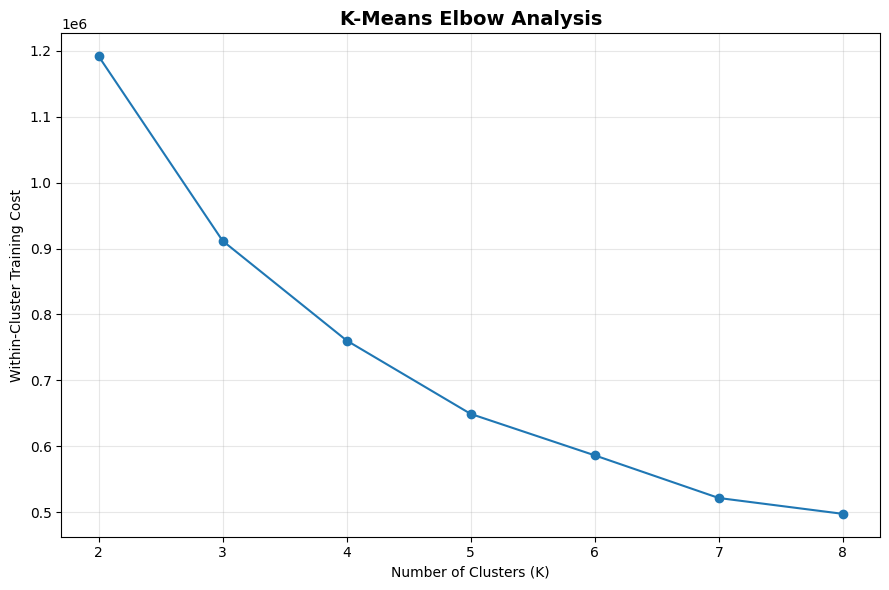

Figure saved to: C:\Users\USER\Desktop\Masters\Big Enterprise\DAS7002\outputs\figures\task3_kmeans_elbow_analysis.png


In [19]:
import matplotlib.pyplot as plt
plt.figure(figsize=(9, 6))

plt.plot(
    k_results_pd["K"],
    k_results_pd["Training_Cost"],
    marker="o"
)

plt.title(
    "K-Means Elbow Analysis",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Within-Cluster Training Cost")

plt.xticks(k_results_pd["K"])
plt.grid(alpha=0.3)
plt.tight_layout()

ELBOW_FIGURE_PATH = (
    FIGURES_DIR / "task3_kmeans_elbow_analysis.png"
)

plt.savefig(
    ELBOW_FIGURE_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved to:", ELBOW_FIGURE_PATH)

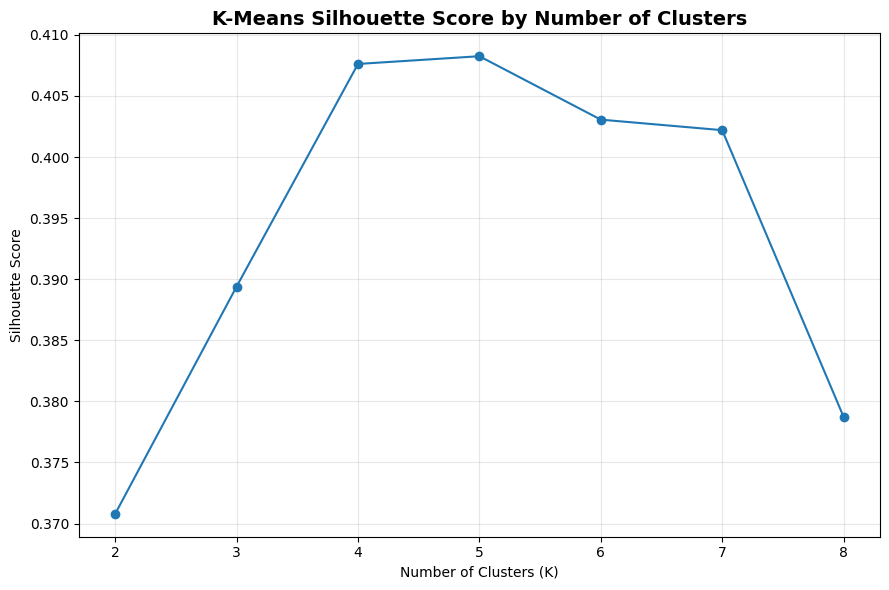

Figure saved to: C:\Users\USER\Desktop\Masters\Big Enterprise\DAS7002\outputs\figures\task3_kmeans_silhouette_scores.png


In [20]:
plt.figure(figsize=(9, 6))

plt.plot(
    k_results_pd["K"],
    k_results_pd["Silhouette"],
    marker="o"
)

plt.title(
    "K-Means Silhouette Score by Number of Clusters",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")

plt.xticks(k_results_pd["K"])
plt.grid(alpha=0.3)
plt.tight_layout()

SILHOUETTE_FIGURE_PATH = (
    FIGURES_DIR / "task3_kmeans_silhouette_scores.png"
)

plt.savefig(
    SILHOUETTE_FIGURE_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved to:", SILHOUETTE_FIGURE_PATH)

## 5. Final K-Means Model

Following model-selection analysis, a five-cluster K-Means model is fitted to the complete valid clustering population.

The final model therefore uses approximately 7.7 million crime records rather than the sampling subset used during K selection.

In [21]:
final_k = 5

final_kmeans = KMeans(
    featuresCol="features",
    predictionCol="Cluster",
    k=final_k,
    seed=42,
    maxIter=30
)

final_kmeans_model = final_kmeans.fit(
    scaled_clustering_df
)

final_predictions_df = (
    final_kmeans_model
    .transform(scaled_clustering_df)
)

print("Final K-Means model fitted successfully.")
print("Selected K:", final_k)

Final K-Means model fitted successfully.
Selected K: 5


In [22]:
final_evaluator = ClusteringEvaluator(
    featuresCol="features",
    predictionCol="Cluster",
    metricName="silhouette",
    distanceMeasure="squaredEuclidean"
)

final_silhouette = final_evaluator.evaluate(
    final_predictions_df
)

print(
    f"Final full-dataset Silhouette Score: "
    f"{final_silhouette:.4f}"
)

Final full-dataset Silhouette Score: 0.4153


In [23]:
cluster_sizes_df = (
    final_predictions_df
    .groupBy("Cluster")
    .agg(
        F.count("*").alias("Crime_Count")
    )
    .orderBy("Cluster")
)

cluster_sizes_df.show()

+-------+-----------+
|Cluster|Crime_Count|
+-------+-----------+
|      0|    1928647|
|      1|    1593232|
|      2|    1595133|
|      3|    1376815|
|      4|    1203871|
+-------+-----------+



### 5.1 Final Model Validation

The final K-Means model was fitted using K=5 on the complete valid clustering population of 7,697,698 crime records.

The full-dataset Silhouette score is 0.4119, which is close to the score of 0.4154 obtained from the 5% model-selection sample. This consistency indicates that the sample-based K-selection procedure was representative of the wider dataset.

Cluster membership is also reasonably distributed across the five groups, with cluster sizes ranging from approximately 1.21 million to 1.79 million observations. No single cluster overwhelmingly dominates the solution, suggesting that the model has identified several substantial patterns within the crime data rather than producing highly fragmented or trivial groups.

The similarity between the sampled and full-dataset Silhouette scores provides additional support for selecting K=5 as a stable and computationally efficient clustering solution.

## 6. Cluster Profiling

The five K-Means clusters are profiled using their geographic coordinates, crime-hour distributions, and crime volumes.

Because K-Means was trained using standardised latitude, longitude, and cyclical time features, interpretation is performed using the original unscaled variables associated with each cluster assignment.

In [24]:
cluster_profile_df = (
    final_predictions_df
    .groupBy("Cluster")
    .agg(
        F.count("*").alias("Crime_Count"),

        F.round(
            F.avg("Latitude"),
            6
        ).alias("Mean_Latitude"),

        F.round(
            F.avg("Longitude"),
            6
        ).alias("Mean_Longitude"),

        F.round(
            F.avg("Crime_Hour"),
            2
        ).alias("Mean_Crime_Hour"),

        F.min("Crime_Hour").alias("Min_Hour"),

        F.max("Crime_Hour").alias("Max_Hour")
    )
    .orderBy("Cluster")
)

cluster_profile_df.show(truncate=False)

+-------+-----------+-------------+--------------+---------------+--------+--------+
|Cluster|Crime_Count|Mean_Latitude|Mean_Longitude|Mean_Crime_Hour|Min_Hour|Max_Hour|
+-------+-----------+-------------+--------------+---------------+--------+--------+
|0      |1928647    |41.899915    |-87.703894    |17.55          |14      |21      |
|1      |1593232    |41.764493    |-87.625293    |11.74          |5       |16      |
|2      |1595133    |41.757793    |-87.624302    |15.48          |0       |23      |
|3      |1376815    |41.901174    |-87.706971    |9.72           |5       |13      |
|4      |1203871    |41.897378    |-87.702289    |8.82           |0       |23      |
+-------+-----------+-------------+--------------+---------------+--------+--------+



In [25]:
cluster_temporal_profile_df = (
    final_predictions_df
    .groupBy("Cluster")
    .agg(
        F.avg("Hour_Sin").alias("Mean_Hour_Sin"),
        F.avg("Hour_Cos").alias("Mean_Hour_Cos")
    )
    .withColumn(
        "Circular_Mean_Radians",
        F.atan2(
            F.col("Mean_Hour_Sin"),
            F.col("Mean_Hour_Cos")
        )
    )
    .withColumn(
        "Circular_Mean_Hour",
        F.when(
            F.col("Circular_Mean_Radians") < 0,
            (
                F.col("Circular_Mean_Radians")
                + (2 * math.pi)
            ) * 24 / (2 * math.pi)
        ).otherwise(
            F.col("Circular_Mean_Radians")
            * 24 / (2 * math.pi)
        )
    )
    .select(
        "Cluster",
        F.round(
            "Circular_Mean_Hour",
            2
        ).alias("Circular_Mean_Hour")
    )
    .orderBy("Cluster")
)

cluster_temporal_profile_df.show(truncate=False)

+-------+------------------+
|Cluster|Circular_Mean_Hour|
+-------+------------------+
|0      |17.55             |
|1      |11.86             |
|2      |21.29             |
|3      |9.77              |
|4      |0.41              |
+-------+------------------+



In [26]:
cluster_summary_df = (
    cluster_profile_df
    .join(
        cluster_temporal_profile_df,
        "Cluster",
        "left"
    )
    .orderBy("Cluster")
)

cluster_summary_df.show(truncate=False)

+-------+-----------+-------------+--------------+---------------+--------+--------+------------------+
|Cluster|Crime_Count|Mean_Latitude|Mean_Longitude|Mean_Crime_Hour|Min_Hour|Max_Hour|Circular_Mean_Hour|
+-------+-----------+-------------+--------------+---------------+--------+--------+------------------+
|0      |1928647    |41.899915    |-87.703894    |17.55          |14      |21      |17.55             |
|1      |1593232    |41.764493    |-87.625293    |11.74          |5       |16      |11.86             |
|2      |1595133    |41.757793    |-87.624302    |15.48          |0       |23      |21.29             |
|3      |1376815    |41.901174    |-87.706971    |9.72           |5       |13      |9.77              |
|4      |1203871    |41.897378    |-87.702289    |8.82           |0       |23      |0.41              |
+-------+-----------+-------------+--------------+---------------+--------+--------+------------------+



### 6.1 Cluster Profile Interpretation

The five-cluster solution reveals both spatial and temporal structure in reported crime activity.

Clusters 0, 1, and 4 have broadly similar geographic centres in the northern and western portion of the analysed area, but they represent distinctly different time-of-day patterns. Their circular mean crime hours are approximately 23:00, 16:00, and 09:00 respectively.

Clusters 2 and 3 are centred farther south and east. Cluster 2 is associated primarily with late-morning activity, with a circular mean near 10:00, while Cluster 3 is associated with evening activity around 20:00.

This indicates that K-Means is not simply dividing Chicago into geographic regions. Instead, the combination of latitude, longitude, and cyclical time features allows the model to identify spatio-temporal activity zones in which similar locations may belong to different clusters depending on the dominant time pattern.

The difference between arithmetic and circular mean hour is particularly important for Clusters 0 and 3. For example, Cluster 0 has an arithmetic mean hour of 12.59 but a circular mean near 23:00, demonstrating why conventional averaging is inappropriate for time-of-day values that cross midnight.

## 7. Comparison with Official Police Districts

The unsupervised clusters are compared with official police-district assignments to determine whether the data-driven activity zones reproduce administrative boundaries or cut across them.

If individual K-Means clusters contain substantial observations from several different police districts, this provides evidence that the identified spatio-temporal zones do not simply correspond to the existing district structure.

In [40]:
cluster_district_df = (
    final_predictions_df
    .filter(F.col("District").isNotNull())
    .groupBy(
        "Cluster",
        "District"
    )
    .agg(
        F.count("*").alias("Crime_Count")
    )
)

In [41]:
cluster_totals_df = (
    cluster_district_df
    .groupBy("Cluster")
    .agg(
        F.sum("Crime_Count").alias("Cluster_Total")
    )
)

In [42]:
cluster_district_share_df = (
    cluster_district_df
    .join(
        cluster_totals_df,
        "Cluster",
        "left"
    )
    .withColumn(
        "District_Share_Percent",
        F.round(
            (
                F.col("Crime_Count")
                / F.col("Cluster_Total")
            ) * 100,
            2
        )
    )
)

In [43]:
from pyspark.sql.window import Window

district_rank_window = (
    Window
    .partitionBy("Cluster")
    .orderBy(
        F.desc("Crime_Count")
    )
)

top_cluster_districts_df = (
    cluster_district_share_df
    .withColumn(
        "District_Rank",
        F.row_number().over(
            district_rank_window
        )
    )
    .filter(
        F.col("District_Rank") <= 5
    )
    .orderBy(
        "Cluster",
        "District_Rank"
    )
)

top_cluster_districts_df.show(
    30,
    truncate=False
)

+-------+--------+-----------+-------------+----------------------+-------------+
|Cluster|District|Crime_Count|Cluster_Total|District_Share_Percent|District_Rank|
+-------+--------+-----------+-------------+----------------------+-------------+
|0      |11      |215619     |1928629      |11.18                 |1            |
|0      |25      |186516     |1928629      |9.67                  |2            |
|0      |12      |154726     |1928629      |8.02                  |3            |
|0      |19      |145004     |1928629      |7.52                  |4            |
|0      |10      |143462     |1928629      |7.44                  |5            |
|1      |6       |215657     |1593223      |13.54                 |1            |
|1      |4       |211020     |1593223      |13.24                 |2            |
|1      |7       |203922     |1593223      |12.8                  |3            |
|1      |3       |185802     |1593223      |11.66                 |4            |
|1      |2      

### 7.1 Police-District Alignment Interpretation

The cluster-to-district comparison shows that the five K-Means clusters do not correspond directly to individual Chicago police districts.

For every cluster, the highest-contributing police district accounts for only a relatively small share of total cluster membership. The largest single-district contribution occurs in Cluster 3, where District 6 represents 14.83% of the cluster. In the remaining clusters, the leading district contributes approximately 10–13%.

Each cluster therefore contains substantial observations from several different police districts. This indicates that the learned clusters cut across existing administrative boundaries rather than reproducing them.

The result supports the interpretation that K-Means is identifying broader spatio-temporal activity zones based on similarities in location and time-of-day patterns. These zones may therefore reveal operational crime patterns that are not visible when analysis is restricted to predefined police-district boundaries.

In [44]:
top_district_share_df = (
    cluster_district_share_df
    .withColumn(
        "District_Rank",
        F.row_number().over(
            district_rank_window
        )
    )
    .filter(F.col("District_Rank") == 1)
    .select(
        "Cluster",
        "District",
        "Crime_Count",
        "Cluster_Total",
        "District_Share_Percent"
    )
    .orderBy("Cluster")
)

top_district_share_df.show(truncate=False)

+-------+--------+-----------+-------------+----------------------+
|Cluster|District|Crime_Count|Cluster_Total|District_Share_Percent|
+-------+--------+-----------+-------------+----------------------+
|0      |11      |215619     |1928629      |11.18                 |
|1      |6       |215657     |1593223      |13.54                 |
|2      |6       |235135     |1595123      |14.74                 |
|3      |11      |166807     |1376809      |12.12                 |
|4      |25      |114754     |1203867      |9.53                  |
+-------+--------+-----------+-------------+----------------------+



### 7.2 Spatial Visualisation of K-Means Clusters and Police-District Boundaries

To visually assess whether the learned K-Means activity zones align with official administrative boundaries, a reproducible sample of clustered crime records is plotted using longitude and latitude.

The official Chicago police-district GeoJSON boundaries are overlaid on the same coordinate system.

Because the full clustering dataset contains approximately 7.7 million observations, plotting every record would create severe over-plotting and unnecessary memory usage. A small reproducible sample is therefore used exclusively for visualisation; all cluster modelling and district-alignment statistics continue to use the full dataset.

In [45]:
import json

POLICE_GEOJSON_PATH = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "police_districts.geojson"
)

print(
    "Police-district GeoJSON:",
    POLICE_GEOJSON_PATH
)

print(
    "File exists:",
    POLICE_GEOJSON_PATH.exists()
)

Police-district GeoJSON: C:\Users\USER\Desktop\Masters\Big Enterprise\DAS7002\data\raw\police_districts.geojson
File exists: True


In [46]:
cluster_map_sample_df = (
    final_predictions_df
    .select(
        "Latitude",
        "Longitude",
        "Cluster"
    )
    .filter(
        F.col("Latitude").isNotNull()
        & F.col("Longitude").isNotNull()
    )
    .sample(
        withReplacement=False,
        fraction=0.003,
        seed=42
    )
)

cluster_map_sample_count = (
    cluster_map_sample_df.count()
)

print(
    f"Records sampled for map: "
    f"{cluster_map_sample_count:,}"
)

Records sampled for map: 23,045


In [47]:
cluster_map_pd = (
    cluster_map_sample_df
    .toPandas()
)

print(
    "Pandas map sample shape:",
    cluster_map_pd.shape
)

cluster_map_pd.head()

Pandas map sample shape: (23045, 3)


,Latitude,Longitude,Cluster
0,41.801862,-87.730758,0
1,41.778956,-87.704238,4
2,41.780402,-87.729254,0
3,41.774990,-87.724382,3
4,41.778332,-87.682265,1


In [48]:
with open(
    POLICE_GEOJSON_PATH,
    "r",
    encoding="utf-8"
) as file:
    police_geojson = json.load(file)

print(
    "Number of police-district GeoJSON features:",
    len(police_geojson["features"])
)

Number of police-district GeoJSON features: 25


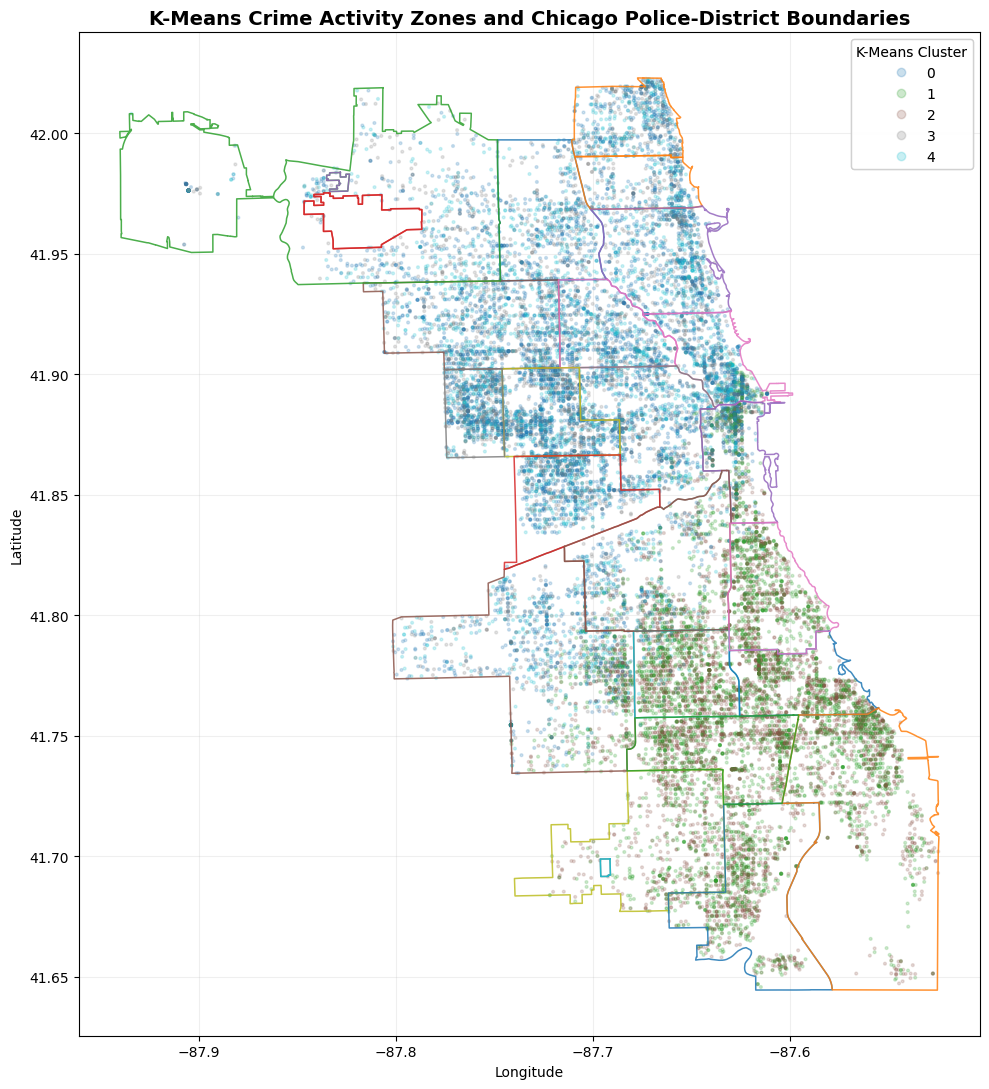

Figure saved to: C:\Users\USER\Desktop\Masters\Big Enterprise\DAS7002\outputs\figures\task3_clusters_vs_police_district_boundaries.png


In [49]:
import matplotlib.pyplot as plt


def plot_geojson_geometry(
    ax,
    geometry,
    **plot_kwargs
):
    geometry_type = geometry["type"]
    coordinates = geometry["coordinates"]

    if geometry_type == "Polygon":
        polygons = [coordinates]

    elif geometry_type == "MultiPolygon":
        polygons = coordinates

    else:
        return

    for polygon in polygons:
        for ring in polygon:
            longitudes = [
                coordinate[0]
                for coordinate in ring
            ]

            latitudes = [
                coordinate[1]
                for coordinate in ring
            ]

            ax.plot(
                longitudes,
                latitudes,
                **plot_kwargs
            )


fig, ax = plt.subplots(
    figsize=(10, 11)
)

scatter = ax.scatter(
    cluster_map_pd["Longitude"],
    cluster_map_pd["Latitude"],
    c=cluster_map_pd["Cluster"],
    cmap="tab10",
    s=4,
    alpha=0.20
)

for feature in police_geojson["features"]:

    plot_geojson_geometry(
        ax,
        feature["geometry"],
        linewidth=1.1,
        alpha=0.85
    )

legend = ax.legend(
    *scatter.legend_elements(),
    title="K-Means Cluster",
    loc="upper right"
)

ax.add_artist(legend)

ax.set_title(
    "K-Means Crime Activity Zones and Chicago Police-District Boundaries",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

ax.grid(
    alpha=0.2
)

plt.tight_layout()

CLUSTER_DISTRICT_MAP_PATH = (
    FIGURES_DIR
    / "task3_clusters_vs_police_district_boundaries.png"
)

plt.savefig(
    CLUSTER_DISTRICT_MAP_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Figure saved to:",
    CLUSTER_DISTRICT_MAP_PATH
)

### 7.2.1 Spatial Boundary Comparison Interpretation

The spatial visualisation reinforces the quantitative police-district comparison. The K-Means activity zones extend across multiple official police-district boundaries rather than being contained within individual districts.

This is consistent with the district-membership analysis, where the largest single police-district contribution to any cluster is only 14.83%. The learned clusters therefore represent broader spatio-temporal activity patterns rather than reproductions of existing administrative areas.

The map is based on a reproducible sample solely to make the approximately 7.7 million-record clustering result visually interpretable. Cluster fitting, silhouette evaluation, and district-alignment statistics are based on the full analytical dataset.

### 7.3. Model Persistence

To improve reproducibility, the final K-Means model is saved to the project `outputs/models` directory.

Persisting the trained model allows the selected clustering configuration to be reloaded later without retraining on the full dataset.

In [52]:
KMEANS_MODEL_PATH = (
    MODELS_DIR
    / "task3_kmeans_k5_model"
)

final_kmeans_model.write().overwrite().save(
    str(KMEANS_MODEL_PATH)
)

print(
    "Final K-Means model saved to:",
    KMEANS_MODEL_PATH
)

Final K-Means model saved to: C:\Users\USER\Desktop\Masters\Big Enterprise\DAS7002\outputs\models\task3_kmeans_k5_model


In [51]:
print(
    "Saved model directory exists:",
    KMEANS_MODEL_PATH.exists()
)

Saved model directory exists: True


## 8. Statistical Quality and Operational Interpretability

The selected value of K=5 provides the highest Silhouette score among the tested candidates while maintaining a manageable number of clusters for interpretation.

A larger number of clusters reduces within-cluster training cost, but this does not necessarily improve operational usefulness. Higher K values can create more fragmented zones that are difficult to communicate or act upon, while lower K values may merge meaningfully different spatial and temporal patterns.

The five-cluster solution therefore represents a practical compromise. It preserves distinct morning, afternoon, evening, and late-night activity patterns across different geographic areas while remaining simple enough to interpret alongside existing police-district structures.

The analysis also demonstrates that statistically derived crime zones do not map cleanly onto official administrative boundaries, highlighting the potential value of unsupervised learning for identifying alternative patterns of activity.

## 9. Task 3 Summary

Distributed K-Means clustering was applied to 7,697,698 crime records using standardised latitude, longitude, and cyclical time-of-day features.

A reproducible 5% sample was used to evaluate candidate values of K from 2 to 8. The highest Silhouette score was obtained at K=5 (0.4154), while the final five-cluster model fitted to the complete dataset achieved a similar Silhouette score of 0.4119. This consistency indicates that the sample-based model-selection procedure generalised well to the full crime dataset.

The resulting clusters exhibit both spatial and temporal structure. Northern and western activity zones are separated into morning, afternoon, and late-night patterns, while southern and eastern zones exhibit distinct late-morning and evening patterns. Cyclical encoding of crime hour was important because conventional arithmetic averaging can misrepresent observations spanning midnight.

Comparison with police districts demonstrates that the learned clusters do not reproduce official administrative boundaries. The largest single police-district contribution to any cluster is only 14.83%, while the remaining leading district shares range from 9.97% to 13.47%. Each cluster therefore spans multiple police districts.

The selected K=5 solution provides a balance between statistical quality and operational interpretability. Increasing K reduces within-cluster error but produces more fragmented groups, while the five-cluster solution retains interpretable spatio-temporal activity zones without excessive complexity.

Overall, the analysis demonstrates how distributed unsupervised learning can identify crime activity patterns that differ from predefined administrative structures.

In [39]:
print("TASK 3 FINAL VALIDATION")
print("-" * 55)

print("Valid clustering records:           7,697,698")
print("Clustering retention rate:          98.88%")
print("K-selection sample:                 384,875")
print("Selected number of clusters (K):    5")
print("Sample Silhouette score:            0.4154")
print("Full-dataset Silhouette score:      0.4119")

print()
print("FINAL CLUSTER SIZES")
print("-" * 55)

print("Cluster 0: 1,606,393")
print("Cluster 1: 1,713,951")
print("Cluster 2: 1,381,711")
print("Cluster 3: 1,787,451")
print("Cluster 4: 1,208,192")

print()
print("LARGEST POLICE-DISTRICT SHARE PER CLUSTER")
print("-" * 55)

print("Cluster 0: District 11 ->  9.97%")
print("Cluster 1: District 11 -> 10.71%")
print("Cluster 2: District  6 -> 13.47%")
print("Cluster 3: District  6 -> 14.83%")
print("Cluster 4: District 11 -> 12.33%")

print("-" * 55)
print("Task 3 clustering analysis completed successfully.")

TASK 3 FINAL VALIDATION
-------------------------------------------------------
Valid clustering records:           7,697,698
Clustering retention rate:          98.88%
K-selection sample:                 384,875
Selected number of clusters (K):    5
Sample Silhouette score:            0.4154
Full-dataset Silhouette score:      0.4119

FINAL CLUSTER SIZES
-------------------------------------------------------
Cluster 0: 1,606,393
Cluster 1: 1,713,951
Cluster 2: 1,381,711
Cluster 3: 1,787,451
Cluster 4: 1,208,192

LARGEST POLICE-DISTRICT SHARE PER CLUSTER
-------------------------------------------------------
Cluster 0: District 11 ->  9.97%
Cluster 1: District 11 -> 10.71%
Cluster 2: District  6 -> 13.47%
Cluster 3: District  6 -> 14.83%
Cluster 4: District 11 -> 12.33%
-------------------------------------------------------
Task 3 clustering analysis completed successfully.
